# EDA — Dataset de deserción en educación superior (Colombia)

Análisis exploratorio del dataset integrado por el ETL (`pipeline.py`).

**Alcance y limitación.** No existen datos abiertos de deserción por estudiante ni por municipio en educación
superior. La variable objetivo (tasa de deserción de SPADIES) es **institucional**, y las variables explicativas
son territoriales (Saber 11, SNIES, DANE/TerriData) del año **t-1**. El modelo predice **riesgo a nivel
institucional/territorial**, no individual.

Secciones: 1) carga y descripción, 2) variable objetivo, 3) nulos por fuente, 4) relación variables–objetivo,
5) mapa de municipios.

In [1]:
# Configuración básica: rutas relativas a la raíz del proyecto y librerías
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.config import load_config
from src.validate.dictionary import describir_columnas

cfg = load_config(RAIZ / "config" / "config.yaml")
unidad = cfg["unidad_analisis"]
ruta = RAIZ / cfg["rutas"]["processed"] / f"dataset_{unidad}.csv"
print("Unidad de análisis:", unidad, "| archivo:", ruta.name)

Unidad de análisis: municipio | archivo: dataset_municipio.csv


## 1. Carga y descripción general

In [2]:
# Los códigos son texto: se leen como str para conservar los ceros a la izquierda (ej. 05001)
df = pd.read_csv(ruta, dtype={"cod_divipola_mpio": str, "cod_ies": str, "cod_snies_programa": str})
print(f"{df.shape[0]} filas x {df.shape[1]} columnas | años: {df['anio'].min()}–{df['anio'].max()}")
df.head()

3074 filas x 10 columnas | años: 2015–2021


,cod_divipola_mpio,anio,tasa_desercion,punt_global_media_t1,punt_global_mediana_t1,pct_estrato_bajo_t1,pct_colegio_oficial_t1,n_estudiantes_t1,mpio_matriculados_t1,mpio_ies_con_oferta_t1
0,05001,2015,NaN,254.395442,250.0,0.588256,0.568989,30055.0,236689.0,47.0
1,05001,2016,NaN,252.283323,247.0,0.602840,0.563434,31127.0,242671.0,51.0
2,05001,2017,NaN,263.103326,263.0,0.590356,0.614498,29315.0,249976.0,48.0
3,05001,2018,NaN,259.877722,259.0,0.570179,0.620212,28795.0,254651.0,49.0
4,05001,2019,NaN,NaN,NaN,NaN,NaN,NaN,260864.0,48.0


In [3]:
# Tipos de dato y resumen estadístico de las variables numéricas
display(df.dtypes.to_frame("tipo").T)
df.describe().T

,cod_divipola_mpio,anio,tasa_desercion,punt_global_media_t1,punt_global_mediana_t1,pct_estrato_bajo_t1,pct_colegio_oficial_t1,n_estudiantes_t1,mpio_matriculados_t1,mpio_ies_con_oferta_t1
tipo,str,int64,float64,float64,float64,float64,float64,float64,float64,float64


,count,mean,std,min,25%,50%,75%,max
anio,3074.0,2017.765127,2.058723,2015.000000,2016.000000,2018.000000,2020.000000,2021.00000
tasa_desercion,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
punt_global_media_t1,2185.0,243.613141,17.907057,163.154930,231.816568,243.800000,255.419355,313.68021
punt_global_mediana_t1,2185.0,240.836384,19.208923,157.000000,228.000000,241.000000,253.000000,318.00000
pct_estrato_bajo_t1,2185.0,0.882764,0.136919,0.210345,0.828283,0.923710,0.989011,1.00000
pct_colegio_oficial_t1,2185.0,0.889105,0.146077,0.248882,0.816514,0.952096,1.000000,1.00000
n_estudiantes_t1,2185.0,1077.434783,4910.457606,5.000000,134.000000,300.000000,639.000000,96708.00000
mpio_matriculados_t1,2390.0,6916.428870,45072.844576,1.000000,32.000000,141.000000,1492.750000,804455.00000
mpio_ies_con_oferta_t1,2390.0,4.097490,8.867054,1.000000,1.000000,2.000000,3.000000,126.00000


## 2. Variable objetivo: tasa de deserción

In [4]:
# La tasa viene de SPADIES (export manual). Si aún no existe, el dataset es preliminar y la tasa es nula.
hay_objetivo = df["tasa_desercion"].notna().any()
if hay_objetivo:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    df["tasa_desercion"].plot.hist(bins=30, ax=ax[0], title="Distribución de la tasa de deserción")
    df.groupby("anio")["tasa_desercion"].mean().plot(marker="o", ax=ax[1], title="Tasa media por año")
    plt.tight_layout()
    plt.show()
    print(df["tasa_desercion"].describe())
else:
    print("AVISO: tasa_desercion es nula en todo el dataset (falta el export de SPADIES en data/raw/spadies/).")
    print("Las secciones que dependen del objetivo se omiten; el resto describe las variables explicativas.")

AVISO: tasa_desercion es nula en todo el dataset (falta el export de SPADIES en data/raw/spadies/).
Las secciones que dependen del objetivo se omiten; el resto describe las variables explicativas.


## 3. Valores nulos por fuente

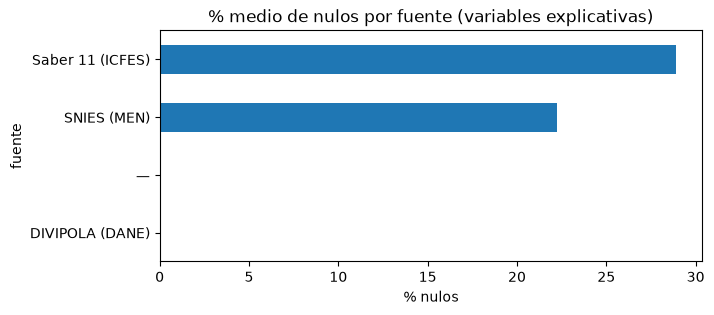

,pct_nulos,fuente
tasa_desercion,100.000000,SPADIES (MEN)
punt_global_media_t1,28.919974,Saber 11 (ICFES)
pct_colegio_oficial_t1,28.919974,Saber 11 (ICFES)
n_estudiantes_t1,28.919974,Saber 11 (ICFES)
punt_global_mediana_t1,28.919974,Saber 11 (ICFES)
pct_estrato_bajo_t1,28.919974,Saber 11 (ICFES)
mpio_matriculados_t1,22.251139,SNIES (MEN)
mpio_ies_con_oferta_t1,22.251139,SNIES (MEN)
anio,0.000000,—
cod_divipola_mpio,0.000000,DIVIPOLA (DANE)


In [5]:
# Se agrupan las columnas por fuente usando el diccionario de datos del ETL
fuentes, _ = describir_columnas(list(df.columns))
nulos = df.isna().mean().mul(100).rename("pct_nulos").to_frame()
nulos["fuente"] = [fuentes.get(c, "—") for c in nulos.index]
por_fuente = nulos[nulos.index != "tasa_desercion"].groupby("fuente")["pct_nulos"].mean().sort_values()
por_fuente.plot.barh(title="% medio de nulos por fuente (variables explicativas)", figsize=(7, 3))
plt.xlabel("% nulos")
plt.show()
nulos.sort_values("pct_nulos", ascending=False).head(10)

**Lectura.** Los nulos de las variables rezagadas en el primer año de la ventana son esperados (no existe t-1).
El resto señala municipios sin estudiantes de Saber 11 o sin oferta de educación superior; se registran en
`reports/etl_log.md` como pérdidas de cada join.

## 4. Relación variables–objetivo

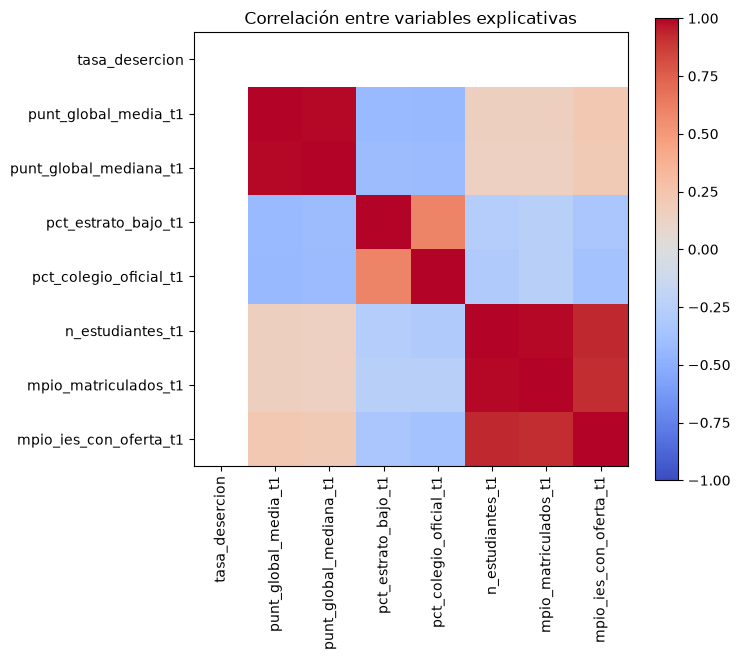

In [6]:
numericas = df.select_dtypes("number").drop(columns=["anio"], errors="ignore")
if hay_objetivo:
    corr = numericas.corr()["tasa_desercion"].drop("tasa_desercion").dropna().sort_values()
    corr.plot.barh(title="Correlación de Pearson con la tasa de deserción", figsize=(7, 4))
    plt.show()
    top = corr.abs().sort_values(ascending=False).head(3).index
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
    for a, c in zip(ax, top):
        a.scatter(df[c], df["tasa_desercion"], s=8, alpha=0.5)
        a.set_xlabel(c); a.set_ylabel("tasa_desercion")
    plt.tight_layout(); plt.show()
else:
    # Sin objetivo: se revisa la correlación entre las variables explicativas
    corr = numericas.corr()
    plt.figure(figsize=(7, 6)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
    plt.colorbar(); plt.title("Correlación entre variables explicativas"); plt.show()

## 5. Mapa de municipios

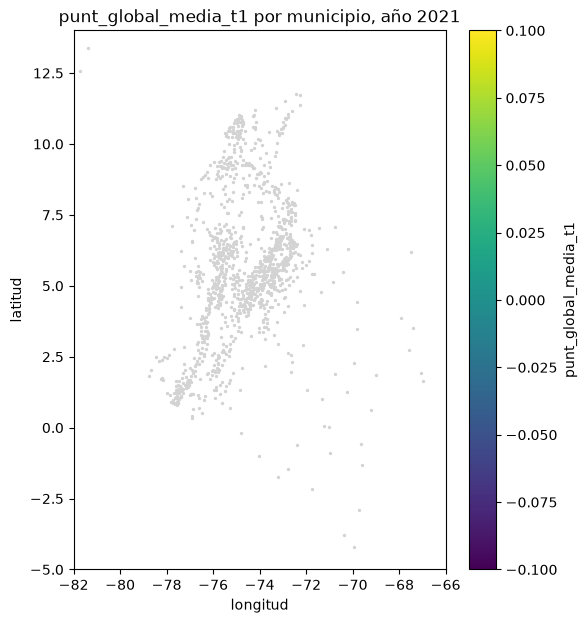

In [7]:
# Coordenadas de DIVIPOLA (usan coma decimal). Se grafican los municipios del dataset coloreados por una variable.
divipola = pd.read_csv(RAIZ / cfg["rutas"]["raw"] / "dane" / "divipola.csv", dtype=str)
for c in ("longitud", "latitud"):
    divipola[c] = pd.to_numeric(divipola[c].str.replace(",", ".", regex=False), errors="coerce")
if "cod_divipola_mpio" in df.columns:
    ultimo = df[df["anio"] == df["anio"].max()]
    variable = "tasa_desercion" if hay_objetivo else "punt_global_media_t1"
    mapa = ultimo.merge(divipola.rename(columns={"cod_mpio": "cod_divipola_mpio"}), on="cod_divipola_mpio", how="left")
    plt.figure(figsize=(6, 7))
    plt.scatter(divipola["longitud"], divipola["latitud"], s=2, c="lightgrey", label="municipios DIVIPOLA")
    puntos = plt.scatter(mapa["longitud"], mapa["latitud"], c=mapa[variable], s=12, cmap="viridis", label="en el dataset")
    plt.colorbar(puntos, label=variable); plt.title(f"{variable} por municipio, año {df['anio'].max()}")
    plt.xlabel("longitud"); plt.ylabel("latitud"); plt.xlim(-82, -66); plt.ylim(-5, 14); plt.show()
else:
    print("La unidad de análisis no es municipio: el mapa requiere cod_divipola_mpio.")

## Conclusiones preliminares

- Documentar aquí el hallazgo principal una vez exista el export de SPADIES (distribución del objetivo, variables más asociadas).
- Riesgo de fuga de datos controlado: todas las variables explicativas son del año t-1.
- Siguiente paso: preprocesamiento (3 metodologías) y modelos, con validación espacial (GroupKFold por departamento) y temporal.